# 07. Real-time forecast with the pipeline

Same steps as `05_Real_time_data.ipynb`, but nothing is redefined here.
Everything comes from the pipeline, so live data goes through **the same feature code as training**:

* `modeling/live_pipeline.py` → fetch live data, create features, pick the latest day
* `modeling/realtime_pipeline.py` → fetching and cleaning (used by `live_pipeline`)
* `modeling/hydro_pipeline.py` → the feature function used for training **and** live data
* `modeling/kaub_pipeline.py` → load the saved model

Needs internet (Pegelonline + Open-Meteo).

In [1]:
# Import libraries and the pipelines
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from modeling import live_pipeline as lp
from modeling import kaub_pipeline as kp
from modeling import hydro_pipeline as hp
from modeling import realtime_pipeline as rp

pd.set_option("display.width", 140)

## 1. Load the saved model

In [2]:
# Load the model the Streamlit app uses (saved by the pipeline)
saved = kp.load_model()

model = saved["model"]
feature_names = list(saved["features"])
horizon = int(saved["horizon"])

print("Model loaded:", kp.MODEL_PATH.name)
print("Forecast horizon:", horizon, "days")
print("Features:", feature_names)

Model loaded: kaub_xgboost_04.joblib
Forecast horizon: 7 days
Features: ['lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_28', 'precip_3d', 'precip_7d', 'precip_14d', 'precip_30d', 'temp_3d', 'temp_7d']


## 2. Fetch live data

In [3]:
# Fetch the last ~30 days of Kaub water level and weather (one row per day)
realtime = lp.fetch_live_daily()

realtime.tail()

,water_level_mean,hours_available,temperature_mean,precipitation_sum
date,,,,
2026-10-10,7.822917,24.0,12.9,2.3
2026-10-11,15.041667,24.0,10.3,1.7
2026-10-12,18.906250,24.0,10.1,0.0
2026-10-13,19.718750,24.0,11.6,1.4
2026-10-14,15.041667,24.0,12.6,0.0


In [4]:
# Check the live data: date range, missing values and incomplete days
print("From:", realtime.index.min().date(), "to", realtime.index.max().date(), f"({len(realtime)} days)")
print("Days without water level:", int(realtime["water_level_mean"].isna().sum()))

realtime.isna().sum()

From: 2026-09-10 to 2026-10-14 (35 days)
Days without water level: 6


water_level_mean     6
hours_available      5
temperature_mean     0
precipitation_sum    0
dtype: int64

## 3. Features (same code as training)

In [5]:
# Create the features with the training feature function (hydro_pipeline.build_features)
live_features = lp.create_live_features(realtime)

live_features[feature_names].tail()

,lag_0,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,precip_3d,precip_7d,precip_14d,precip_30d,temp_3d,temp_7d
date,,,,,,,,,,,,,
2026-10-10,8.0,8.0,1.0,1.0,8.0,-1.0,NaN,13.0,14.0,27.0,32.0,12.333333,13.571429
2026-10-11,15.0,8.0,8.0,1.0,8.0,-1.0,NaN,6.0,16.0,29.0,34.0,11.000000,13.000000
2026-10-12,19.0,15.0,8.0,8.0,6.0,2.0,NaN,4.0,16.0,29.0,34.0,11.000000,12.285714
2026-10-13,20.0,19.0,15.0,8.0,2.0,2.0,NaN,3.0,17.0,30.0,32.0,10.666667,12.000000
2026-10-14,15.0,20.0,19.0,15.0,1.0,-1.0,27.0,1.0,16.0,30.0,32.0,11.666667,11.714286


In [6]:
# Check: live features are identical to training features and to the old realtime code
training_version = kp.make_features(realtime)[feature_names]
old_realtime_version = rp.create_live_features(realtime)[feature_names]

pd.testing.assert_frame_equal(live_features[feature_names], training_version)
pd.testing.assert_frame_equal(live_features[feature_names], old_realtime_version)

print("Live features = training features = old realtime features")

Live features = training features = old realtime features


In [7]:
# Pick the latest complete day as model input (stops if any history is missing)
X_live = lp.latest_inputs(live_features, feature_names)

X_live

,lag_0,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,precip_3d,precip_7d,precip_14d,precip_30d,temp_3d,temp_7d
date,,,,,,,,,,,,,
2026-10-14,15.0,20.0,19.0,15.0,1.0,-1.0,27.0,1.0,16.0,30.0,32.0,11.666667,11.714286


## 4. Forecast

In [8]:
# Forecast the water level 7 days ahead
prediction = float(model.predict(X_live)[0])

reference_date = pd.Timestamp(X_live.index[0])
forecast_date = reference_date + pd.Timedelta(days=horizon)
low_water = prediction < hp.LOW_WATER_CM

print(f"Latest observation: {reference_date.date()}  ({X_live['lag_0'].iloc[0]:.0f} cm)")
print(f"Forecast date:      {forecast_date.date()}")
print(f"Forecast:           {prediction:.1f} cm")
print(f"Low-water alarm (< {hp.LOW_WATER_CM} cm):", "YES" if low_water else "no")

Latest observation: 2026-10-14  (15 cm)
Forecast date:      2026-10-21
Forecast:           51.9 cm
Low-water alarm (< 77 cm): YES


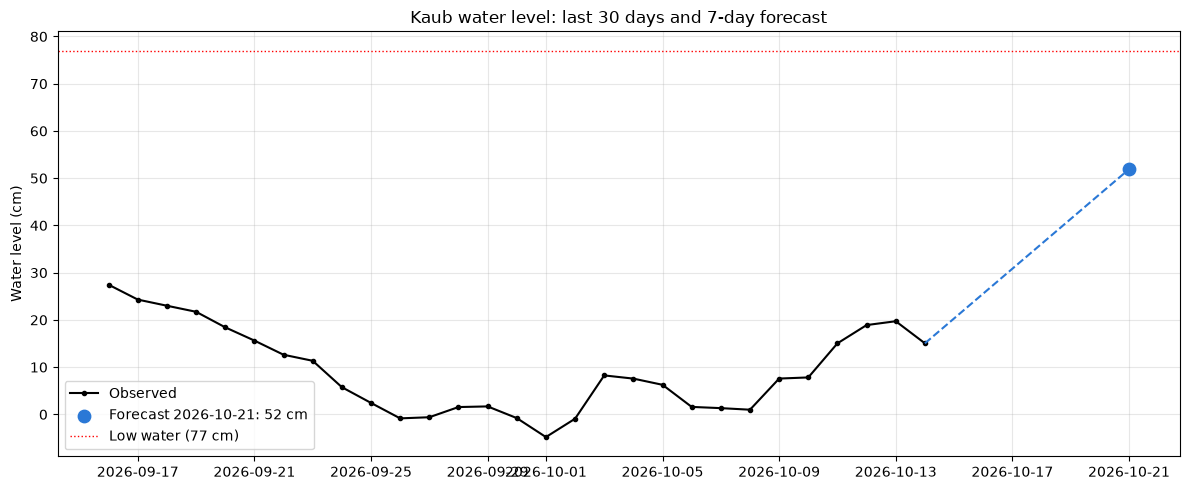

In [9]:
# Plot the last 30 days and the 7-day-ahead forecast
level = realtime["water_level_mean"].dropna()

plt.figure(figsize=(12, 5))
plt.plot(level.index, level, color="black", marker="o", ms=3, lw=1.5, label="Observed")
plt.plot([reference_date, forecast_date], [level.iloc[-1], prediction],
         color="#2a78d6", ls="--", lw=1.5)
plt.scatter([forecast_date], [prediction], color="#2a78d6", s=80, zorder=3,
            label=f"Forecast {forecast_date.date()}: {prediction:.0f} cm")
plt.axhline(hp.LOW_WATER_CM, color="red", ls=":", lw=1, label=f"Low water ({hp.LOW_WATER_CM} cm)")

plt.title("Kaub water level: last 30 days and 7-day forecast")
plt.ylabel("Water level (cm)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Everything in one call

In [10]:
# The same steps in one pipeline call (this is what the Streamlit app would use)
realtime_2, X_live_2 = lp.live_pipeline(feature_names)

print("Same input as above:", X_live_2.equals(X_live))
print(f"Forecast: {model.predict(X_live_2)[0]:.1f} cm")

Same input as above: True
Forecast: 51.9 cm
